# TI3002C – Etapa 5.1: Código ML
**Equipo 6 – Nexxus Consulting**
**Nombre:** Jaime Hernández González
**Matrícula:** A00840312

**Problemática (regresión):** pronosticar las **unidades vendidas (`units_sold`)** de cada producto, en cada región y en cada mes, para que DanuStore planee su inventario con un pronóstico más preciso que el que usa hoy (`units_expected`).

**Modelos:** Random Forest y XGBoost (los dos propuestos en la investigación de la Etapa 5.1).

## 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_colwidth', None)   # para ver los hiperparámetros completos en las tablas

## 2. Importar datos
Se usa la base **mensual (Nivel Macro)**: 130 productos × 7 regiones × 24 meses (2024–2025).

In [2]:
# Si usas Google Drive, monta tu Drive y cambia la ruta:
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/data_DanuStore_Equipo6_Mensual.csv')

df = pd.read_csv('data_DanuStore_Equipo6_Mensual.csv')
print(df.shape)
df.head()

(21840, 20)


,month,year,product_id,region,units_expected,stock,percentage,units_sold,sales_amount,product_name,category,subcategory,static_price,inventory_key,Ventas_Acumuladas_Mensual,Stock_Restante_Mensual,Cumplimiento_Venta_Esperada,Product_Repeat_Purchase_Rate,Venta_Promedio_Diaria,Dias_Cobertura_Inventario
0,March,2025,39,Bajío,1057,1735,164.14,107,4045.32,Shirts Product 39,Casual Wear,Shirts,45.40,Bajío_39_March_2025,107,1628,10.12,99.92,3.451613,502.66
1,October,2025,46,Ciudad de México,1983,3215,162.13,671,49978.14,Pants Product 46,Casual Wear,Pants,87.10,Ciudad de México_46_October_2025,671,2544,33.84,99.89,21.645161,148.53
2,May,2025,113,Ciudad de México,2549,4030,158.10,693,52325.53,Boots Product 113,Footwear,Boots,88.06,Ciudad de México_113_May_2025,693,3337,27.19,99.88,22.354839,180.27
3,February,2025,75,Ciudad de México,1388,2192,157.93,355,23911.75,Jewelry Product 75,Accessories,Jewelry,79.43,Ciudad de México_75_February_2025,355,1837,25.58,99.84,12.678571,172.89
4,October,2025,84,Ciudad de México,1458,2298,157.61,467,18204.74,Hats Product 84,Accessories,Hats,44.88,Ciudad de México_84_October_2025,467,1831,32.03,99.78,15.064516,152.54


### 2.0 Exploración inicial
Revisamos el tamaño de la base, los tipos de datos, si hay valores nulos o registros duplicados, y las estadísticas básicas de la variable objetivo.

In [3]:
print('Filas y columnas:', df.shape)
print('Valores nulos en toda la base:', df.isnull().sum().sum())
print('Registros duplicados:', df.duplicated().sum())
print('Productos:', df['product_id'].nunique(), '| Regiones:', df['region'].nunique(), '| Categorías:', df['category'].nunique())
df.dtypes

Filas y columnas: (21840, 20)
Valores nulos en toda la base: 0
Registros duplicados: 0
Productos: 130 | Regiones: 7 | Categorías: 4


month                               str
year                              int64
product_id                        int64
region                              str
units_expected                    int64
stock                             int64
percentage                      float64
units_sold                        int64
sales_amount                    float64
product_name                        str
category                            str
subcategory                         str
static_price                    float64
inventory_key                       str
Ventas_Acumuladas_Mensual         int64
Stock_Restante_Mensual            int64
Cumplimiento_Venta_Esperada     float64
Product_Repeat_Purchase_Rate    float64
Venta_Promedio_Diaria           float64
Dias_Cobertura_Inventario       float64
dtype: object

In [4]:
df[['units_sold', 'units_expected', 'stock', 'static_price']].describe().round(2)

,units_sold,units_expected,stock,static_price
count,21840.00,21840.00,21840.00,21840.00
mean,207.55,1222.49,1358.55,83.64
std,175.59,434.38,566.11,44.36
min,15.00,323.00,120.00,21.99
25%,81.00,888.75,930.00,48.67
50%,138.50,1192.00,1279.00,77.18
75%,286.00,1507.00,1703.00,104.50
max,1240.00,3111.00,4732.00,231.68


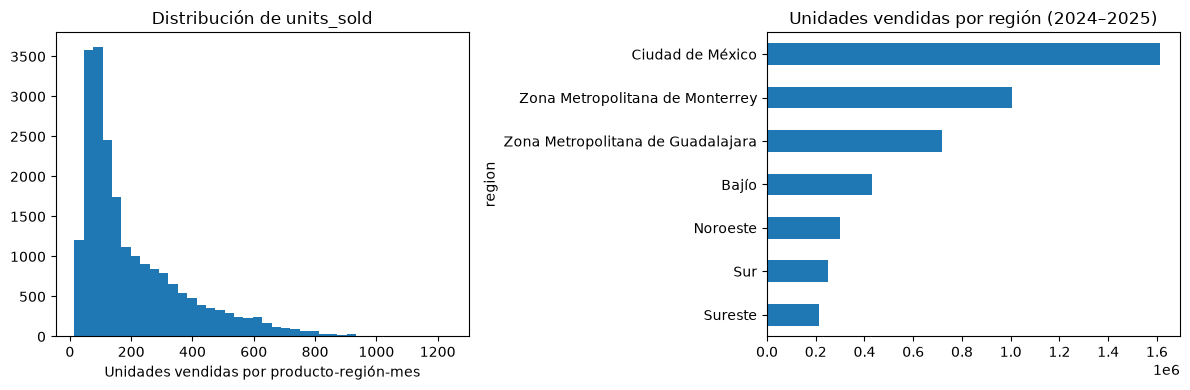

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(df['units_sold'], bins=40)
ax[0].set_title('Distribución de units_sold')
ax[0].set_xlabel('Unidades vendidas por producto-región-mes')

df.groupby('region')['units_sold'].sum().sort_values().plot(kind='barh', ax=ax[1])
ax[1].set_title('Unidades vendidas por región (2024–2025)')
plt.tight_layout()
plt.show()

**Interpretación:** la base no tiene nulos ni duplicados. `units_sold` tiene sesgo a la derecha (la mayoría de los registros vende poco y pocos venden mucho) y las ventas se concentran en CDMX, Monterrey y Guadalajara, por lo que la **región** será una variable importante.

### 2.1 Preparar la fecha
La columna `month` viene como texto (January, February…). La convertimos a número y creamos una fecha para poder ordenar los datos en el tiempo.

In [6]:
meses = {'January': 1, 'February': 2, 'March': 3, 'April': 4, 'May': 5, 'June': 6,
         'July': 7, 'August': 8, 'September': 9, 'October': 10, 'November': 11, 'December': 12}

df['mes'] = df['month'].map(meses)
df['fecha'] = pd.to_datetime(dict(year=df['year'], month=df['mes'], day=1))

# Ordenar por producto, región y fecha
df = df.sort_values(['product_id', 'region', 'fecha']).reset_index(drop=True)
df[['product_id', 'region', 'fecha', 'units_sold', 'units_expected']].head()

,product_id,region,fecha,units_sold,units_expected
0,1,Bajío,2024-01-01,136,1398
1,1,Bajío,2024-02-01,161,1456
2,1,Bajío,2024-03-01,148,1363
3,1,Bajío,2024-04-01,161,1283
4,1,Bajío,2024-05-01,177,1367


### 2.2 Las ventas a través del tiempo
Antes de modelar vemos cómo se comportan las ventas reales contra lo que DanuStore esperaba vender.

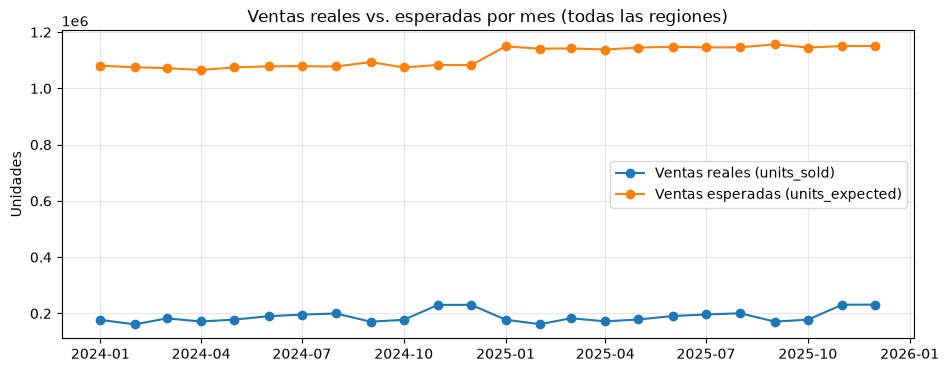

Se vendió el 17.0 % de lo esperado


In [7]:
por_mes = df.groupby('fecha')[['units_sold', 'units_expected']].sum()

plt.figure(figsize=(11, 4))
plt.plot(por_mes.index, por_mes['units_sold'], marker='o', label='Ventas reales (units_sold)')
plt.plot(por_mes.index, por_mes['units_expected'], marker='o', label='Ventas esperadas (units_expected)')
plt.title('Ventas reales vs. esperadas por mes (todas las regiones)')
plt.ylabel('Unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Se vendió el', round(por_mes['units_sold'].sum() / por_mes['units_expected'].sum() * 100, 1), '% de lo esperado')

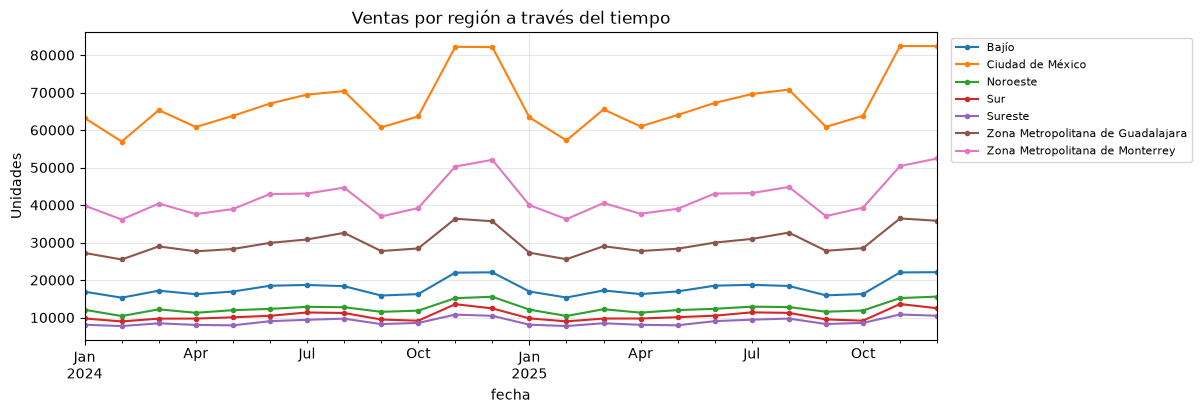

In [8]:
por_region_mes = df.groupby(['fecha', 'region'])['units_sold'].sum().unstack()

por_region_mes.plot(figsize=(11, 4), marker='.')
plt.title('Ventas por región a través del tiempo')
plt.ylabel('Unidades')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.grid(alpha=0.3)
plt.show()

**Interpretación:** el pronóstico actual (`units_expected`) es casi plano y muy superior a las ventas reales, mientras que las ventas sí tienen picos (noviembre y diciembre) en todas las regiones, y el patrón de 2025 es igual al de 2024. Esto confirma que hace falta un modelo que aprenda el comportamiento real de las ventas.

## 3. Selección de variables
### 3.1 Universo de variables
- **Variable objetivo (y):** `units_sold`.
- **Variables candidatas:** `region`, `category`, `subcategory`, `mes`, `static_price` y las **ventas de meses anteriores** (rezagos), que creamos a continuación.

Para pronosticar el mes siguiente solo podemos usar información que **ya conocemos**. Por eso creamos:
- `ventas_mes_anterior`: ventas del mes pasado (t−1).
- `ventas_hace_2` y `ventas_hace_3`: ventas de hace 2 y 3 meses.
- `promedio_3_meses`: promedio de los 3 meses anteriores.

In [9]:
# Agrupamos por producto y región para que cada serie use SUS propias ventas pasadas
grupo = df.groupby(['product_id', 'region'])['units_sold']

df['ventas_mes_anterior'] = grupo.shift(1)
df['ventas_hace_2'] = grupo.shift(2)
df['ventas_hace_3'] = grupo.shift(3)
df['promedio_3_meses'] = (df['ventas_mes_anterior'] + df['ventas_hace_2'] + df['ventas_hace_3']) / 3
df['ventas_hace_12'] = grupo.shift(12)   # mismo mes del año pasado (solo para revisarla)

df[['product_id', 'region', 'fecha', 'units_sold', 'ventas_mes_anterior', 'promedio_3_meses']].head(6)

,product_id,region,fecha,units_sold,ventas_mes_anterior,promedio_3_meses
0,1,Bajío,2024-01-01,136,NaN,NaN
1,1,Bajío,2024-02-01,161,136.0,NaN
2,1,Bajío,2024-03-01,148,161.0,NaN
3,1,Bajío,2024-04-01,161,148.0,148.333333
4,1,Bajío,2024-05-01,177,161.0,156.666667
5,1,Bajío,2024-06-01,136,177.0,162.000000


### 3.2 Variables que NO se pueden usar
Estas variables se calculan **con las ventas del mismo mes** que queremos pronosticar. Si las usamos, el modelo "haría trampa" (fuga de información) porque en la vida real no las conocemos antes de que termine el mes:

| Variable | Por qué se excluye |
|---|---|
| `Ventas_Acumuladas_Mensual` | Es igual a `units_sold` |
| `Venta_Promedio_Diaria` | Es `units_sold` ÷ días del mes |
| `sales_amount` | Es `units_sold` × precio |
| `Cumplimiento_Venta_Esperada` | Es `units_sold` ÷ `units_expected` |
| `Dias_Cobertura_Inventario` | Usa la venta promedio diaria |
| `Stock_Restante_Mensual` | Es stock − `units_sold` |

`units_expected` tampoco se usa como variable: se usa como **punto de comparación** (es el pronóstico actual de la empresa).

### 3.3 Correlaciones más importantes

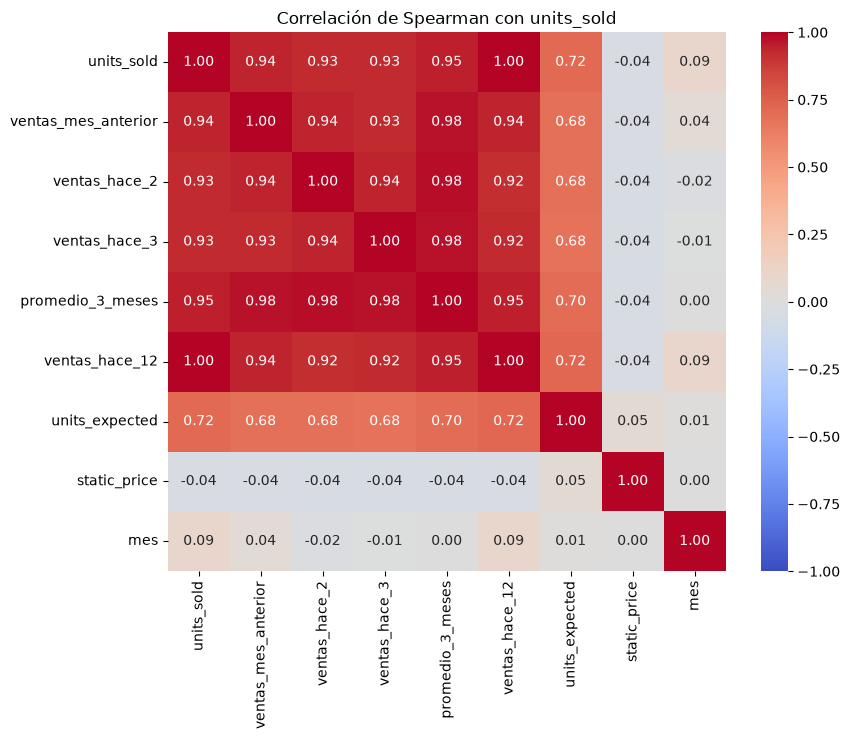

units_sold             1.000
ventas_hace_12         1.000
promedio_3_meses       0.950
ventas_mes_anterior    0.939
ventas_hace_3          0.927
ventas_hace_2          0.927
units_expected         0.715
mes                    0.093
static_price          -0.038
Name: units_sold, dtype: float64


In [10]:
variables_numericas = ['units_sold', 'ventas_mes_anterior', 'ventas_hace_2', 'ventas_hace_3',
                       'promedio_3_meses', 'ventas_hace_12', 'units_expected', 'static_price', 'mes']

correlacion = df[variables_numericas].corr(method='spearman')

plt.figure(figsize=(9, 7))
sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlación de Spearman con units_sold')
plt.show()

print(correlacion['units_sold'].sort_values(ascending=False).round(3))

In [11]:
# ¿Las ventas de 2025 se parecen a las de 2024?
tabla = df.pivot_table(index=['product_id', 'region', 'mes'], columns='year', values='units_sold')
iguales = (tabla[2024] == tabla[2025]).mean() * 100
print('Registros donde las ventas de 2025 son IGUALES a las de 2024:', round(iguales, 1), '%')
print('Diferencia promedio entre 2025 y 2024:', round((tabla[2025] - tabla[2024]).abs().mean(), 2), 'unidades')

Registros donde las ventas de 2025 son IGUALES a las de 2024: 76.6 %
Diferencia promedio entre 2025 y 2024: 0.61 unidades


**Interpretación y selección:**
- Las ventas de los meses anteriores (`ventas_mes_anterior`, `promedio_3_meses`) son las variables más relacionadas con `units_sold`, por eso se seleccionan.
- `units_expected` tiene una correlación menor: ordena bien qué productos venden más, pero no acierta en la cantidad.
- `static_price` y `mes` tienen correlación baja por sí solas, pero se conservan porque los árboles pueden encontrar **combinaciones** (por ejemplo, región × mes) que una correlación no detecta.
- **`ventas_hace_12` NO se usa:** su correlación es prácticamente 1 porque en la base **las ventas de 2025 repiten casi exactamente las de 2024**. Si la usáramos, el modelo solo copiaría el año anterior y no aprendería ningún patrón. Este hallazgo se reportará al socio formador como una observación sobre la calidad de los datos.

**Variables seleccionadas:** `region`, `category`, `subcategory`, `mes`, `static_price`, `ventas_mes_anterior`, `ventas_hace_2`, `ventas_hace_3`, `promedio_3_meses`.

## 4. Codificar variables categóricas
Los modelos solo entienden números. `region`, `category` y `subcategory` son texto, así que se convierten con **One-Hot Encoding** (`pd.get_dummies`): se crea una columna de 0 y 1 por cada categoría.

In [12]:
# Quitamos los 3 primeros meses de cada serie (no tienen ventas anteriores para calcular los rezagos)
datos = df.dropna(subset=['promedio_3_meses']).copy()

variables = ['region', 'category', 'subcategory', 'mes', 'static_price',
             'ventas_mes_anterior', 'ventas_hace_2', 'ventas_hace_3', 'promedio_3_meses']

X = pd.get_dummies(datos[variables], columns=['region', 'category', 'subcategory'], dtype=int)
y = datos['units_sold']

print('Registros:', X.shape[0], '| Columnas después de codificar:', X.shape[1])
X.head()

Registros: 19110 | Columnas después de codificar: 30


,mes,static_price,ventas_mes_anterior,ventas_hace_2,ventas_hace_3,promedio_3_meses,region_Bajío,region_Ciudad de México,region_Noroeste,region_Sur,...,subcategory_Bottoms,subcategory_Dresses,subcategory_Hats,subcategory_Jewelry,subcategory_Outerwear,subcategory_Pants,subcategory_Sandals,subcategory_Shirts,subcategory_Sneakers,subcategory_Tops
3,4,35.16,148.0,161.0,136.0,148.333333,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,5,35.16,161.0,148.0,161.0,156.666667,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
5,6,35.16,177.0,161.0,148.0,162.000000,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
6,7,35.16,136.0,177.0,161.0,158.000000,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
7,8,35.16,143.0,136.0,177.0,152.000000,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1


## 5. Normalización / estandarización
**No es necesaria.** Random Forest y XGBoost son modelos de **árboles de decisión**: separan los datos con reglas del tipo "¿ventas del mes anterior > 150?". Esas reglas funcionan igual si la variable está en unidades, en miles o estandarizada, así que la escala no cambia el resultado. La normalización sí sería necesaria en modelos basados en distancias o gradientes, como KNN, regresión regularizada o redes neuronales.

## 6. Partición de los datos (temporal)
Como queremos pronosticar el **futuro**, no se usa una partición aleatoria: se entrena con los meses más antiguos y se prueba con los más recientes. Se prueban **tres particiones** (los datos con rezagos van de abril 2024 a diciembre 2025, 21 meses):
- **80/20:** entrenar hasta agosto 2025 (17 meses) y probar con septiembre–diciembre 2025 (4 meses).
- **70/30:** entrenar hasta junio 2025 (15 meses) y probar con julio–diciembre 2025 (6 meses).
- **60/40:** entrenar hasta abril 2025 (13 meses) y probar con mayo–diciembre 2025 (8 meses).

In [13]:
particiones = {
    '80/20': '2025-09-01',
    '70/30': '2025-07-01',
    '60/40': '2025-05-01',
}

for nombre, corte in particiones.items():
    entrenamiento = datos['fecha'] < corte
    print(nombre, '-> entrenamiento:', entrenamiento.sum(), 'registros | prueba:', (~entrenamiento).sum(), 'registros')

80/20 -> entrenamiento: 15470 registros | prueba: 3640 registros
70/30 -> entrenamiento: 13650 registros | prueba: 5460 registros
60/40 -> entrenamiento: 11830 registros | prueba: 7280 registros


## 7. Métricas de evaluación
- **MAE:** error promedio en unidades.
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **WAPE:** error total ÷ ventas totales (en %). Es la métrica principal porque se lee fácil: "el pronóstico se equivoca X% de lo que se vende".
- **R²:** qué tanto de la variación de las ventas explica el modelo (1 = perfecto).

In [14]:
def evaluar(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    wape = np.abs(y_real - y_pred).sum() / y_real.sum() * 100
    r2 = r2_score(y_real, y_pred)
    return {'MAE': round(mae, 2), 'RMSE': round(rmse, 2), 'WAPE (%)': round(wape, 2), 'R2': round(r2, 3)}

### 7.1 Puntos de comparación (líneas base)
Un modelo solo sirve si le gana a lo que ya existe:
1. **Pronóstico actual de DanuStore** (`units_expected`).
2. **Modelo ingenuo:** "este mes voy a vender lo mismo que el mes pasado".

In [15]:
resultados = []

for nombre, corte in particiones.items():
    prueba = datos['fecha'] >= corte
    fila = evaluar(y[prueba], datos.loc[prueba, 'units_expected'])
    fila.update({'Modelo': 'Pronóstico actual (units_expected)', 'Partición': nombre, 'Hiperparámetros': '-'})
    resultados.append(fila)

    fila = evaluar(y[prueba], datos.loc[prueba, 'ventas_mes_anterior'])
    fila.update({'Modelo': 'Ingenuo (mes anterior)', 'Partición': nombre, 'Hiperparámetros': '-'})
    resultados.append(fila)

pd.DataFrame(resultados)[['Partición', 'Modelo', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Partición,Modelo,Hiperparámetros,MAE,RMSE,WAPE (%),R2
0,80/20,Pronóstico actual (units_expected),-,1042.04,1093.44,467.95,-32.190
1,80/20,Ingenuo (mes anterior),-,44.15,66.71,19.83,0.876
2,70/30,Pronóstico actual (units_expected),-,1041.87,1093.51,471.23,-33.236
3,70/30,Ingenuo (mes anterior),-,41.23,62.18,18.65,0.889
4,60/40,Pronóstico actual (units_expected),-,1045.73,1097.63,483.00,-35.065
5,60/40,Ingenuo (mes anterior),-,39.34,59.34,18.17,0.895


## 8. Modelo 1: Random Forest
Entrena muchos árboles de decisión, cada uno con una muestra aleatoria de los datos, y **promedia** sus pronósticos.

Hiperparámetros que se prueban:
- `n_estimators`: número de árboles.
- `max_depth`: profundidad máxima de cada árbol (None = sin límite).
- `min_samples_leaf`: mínimo de registros en cada hoja (evita que el árbol memorice).

In [16]:
configuraciones_rf = [
    {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1},
    {'n_estimators': 200, 'max_depth': 15,   'min_samples_leaf': 2},
    {'n_estimators': 300, 'max_depth': 8,    'min_samples_leaf': 5},
]

for nombre, corte in particiones.items():
    entrenamiento = datos['fecha'] < corte
    prueba = datos['fecha'] >= corte

    for config in configuraciones_rf:
        modelo = RandomForestRegressor(**config, random_state=42, n_jobs=-1)
        modelo.fit(X[entrenamiento], y[entrenamiento])
        prediccion = modelo.predict(X[prueba])

        fila = evaluar(y[prueba], prediccion)
        fila.update({'Modelo': 'Random Forest', 'Partición': nombre, 'Hiperparámetros': ', '.join(f'{k}={v}' for k, v in config.items())})
        resultados.append(fila)

tabla_rf = pd.DataFrame(resultados)
tabla_rf[tabla_rf['Modelo'] == 'Random Forest'][['Partición', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Partición,Hiperparámetros,MAE,RMSE,WAPE (%),R2
6,80/20,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.10,20.34,5.88,0.989
7,80/20,"n_estimators=200, max_depth=15, min_samples_leaf=2",16.00,24.26,7.18,0.984
8,80/20,"n_estimators=300, max_depth=8, min_samples_leaf=5",26.74,38.35,12.01,0.959
9,70/30,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.16,20.54,5.95,0.988
10,70/30,"n_estimators=200, max_depth=15, min_samples_leaf=2",17.03,25.47,7.70,0.981
11,70/30,"n_estimators=300, max_depth=8, min_samples_leaf=5",27.09,39.06,12.25,0.956
12,60/40,"n_estimators=100, max_depth=None, min_samples_leaf=1",12.96,20.15,5.98,0.988
13,60/40,"n_estimators=200, max_depth=15, min_samples_leaf=2",16.99,25.15,7.85,0.981
14,60/40,"n_estimators=300, max_depth=8, min_samples_leaf=5",26.93,38.89,12.44,0.955


## 9. Modelo 2: XGBoost
Construye árboles **uno tras otro**; cada árbol nuevo corrige los errores de los anteriores.

Hiperparámetros que se prueban:
- `n_estimators`: número de árboles.
- `learning_rate`: qué tanto corrige cada árbol (más bajo = más lento pero más cuidadoso).
- `max_depth`: profundidad máxima de cada árbol.

In [17]:
configuraciones_xgb = [
    {'n_estimators': 300, 'learning_rate': 0.1,  'max_depth': 6},
    {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 4},
    {'n_estimators': 800, 'learning_rate': 0.03, 'max_depth': 8},
]

for nombre, corte in particiones.items():
    entrenamiento = datos['fecha'] < corte
    prueba = datos['fecha'] >= corte

    for config in configuraciones_xgb:
        modelo = XGBRegressor(**config, random_state=42)
        modelo.fit(X[entrenamiento], y[entrenamiento])
        prediccion = modelo.predict(X[prueba])

        fila = evaluar(y[prueba], prediccion)
        fila.update({'Modelo': 'XGBoost', 'Partición': nombre, 'Hiperparámetros': ', '.join(f'{k}={v}' for k, v in config.items())})
        resultados.append(fila)

tabla_xgb = pd.DataFrame(resultados)
tabla_xgb[tabla_xgb['Modelo'] == 'XGBoost'][['Partición', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Partición,Hiperparámetros,MAE,RMSE,WAPE (%),R2
15,80/20,"n_estimators=300, learning_rate=0.1, max_depth=6",19.73,27.08,8.86,0.980
16,80/20,"n_estimators=500, learning_rate=0.05, max_depth=4",26.16,37.22,11.75,0.962
17,80/20,"n_estimators=800, learning_rate=0.03, max_depth=8",13.21,18.67,5.93,0.990
18,70/30,"n_estimators=300, learning_rate=0.1, max_depth=6",19.90,27.62,9.00,0.978
19,70/30,"n_estimators=500, learning_rate=0.05, max_depth=4",26.17,37.36,11.84,0.960
20,70/30,"n_estimators=800, learning_rate=0.03, max_depth=8",14.10,20.32,6.38,0.988
21,60/40,"n_estimators=300, learning_rate=0.1, max_depth=6",19.58,26.92,9.04,0.978
22,60/40,"n_estimators=500, learning_rate=0.05, max_depth=4",25.79,36.60,11.91,0.960
23,60/40,"n_estimators=800, learning_rate=0.03, max_depth=8",13.52,19.12,6.24,0.989


## 10. Comparación de todos los modelos

In [18]:
tabla_final = pd.DataFrame(resultados)[['Partición', 'Modelo', 'Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]
tabla_final = tabla_final.sort_values(['Partición', 'WAPE (%)']).reset_index(drop=True)
tabla_final

,Partición,Modelo,Hiperparámetros,MAE,RMSE,WAPE (%),R2
0,60/40,Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1",12.96,20.15,5.98,0.988
1,60/40,XGBoost,"n_estimators=800, learning_rate=0.03, max_depth=8",13.52,19.12,6.24,0.989
2,60/40,Random Forest,"n_estimators=200, max_depth=15, min_samples_leaf=2",16.99,25.15,7.85,0.981
3,60/40,XGBoost,"n_estimators=300, learning_rate=0.1, max_depth=6",19.58,26.92,9.04,0.978
4,60/40,XGBoost,"n_estimators=500, learning_rate=0.05, max_depth=4",25.79,36.60,11.91,0.960
5,60/40,Random Forest,"n_estimators=300, max_depth=8, min_samples_leaf=5",26.93,38.89,12.44,0.955
6,60/40,Ingenuo (mes anterior),-,39.34,59.34,18.17,0.895
7,60/40,Pronóstico actual (units_expected),-,1045.73,1097.63,483.00,-35.065
8,70/30,Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.16,20.54,5.95,0.988
9,70/30,XGBoost,"n_estimators=800, learning_rate=0.03, max_depth=8",14.10,20.32,6.38,0.988


In [19]:
# Mejor configuración de cada modelo (menor WAPE) en la partición 70/30
mejores = tabla_final[tabla_final['Partición'] == '70/30'].groupby('Modelo').first().sort_values('WAPE (%)')
mejores[['Hiperparámetros', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Hiperparámetros,MAE,RMSE,WAPE (%),R2
Modelo,,,,,
Random Forest,"n_estimators=100, max_depth=None, min_samples_leaf=1",13.16,20.54,5.95,0.988
XGBoost,"n_estimators=800, learning_rate=0.03, max_depth=8",14.10,20.32,6.38,0.988
Ingenuo (mes anterior),-,41.23,62.18,18.65,0.889
Pronóstico actual (units_expected),-,1041.87,1093.51,471.23,-33.236


## 11. Mejor modelo: resultados
Se vuelve a entrenar el mejor modelo con la partición 70/30 para ver sus resultados con gráficas.

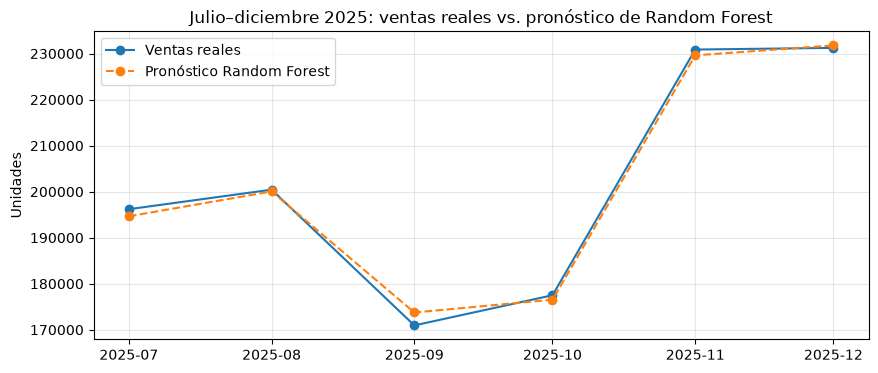

,units_sold,pronostico_rf,units_expected,diferencia_rf,diferencia_actual
fecha,,,,,
2025-07-01,196192,194651.0,1145864,-1541.0,949672
2025-08-01,200436,200050.0,1146348,-386.0,945912
2025-09-01,170951,173754.0,1156597,2803.0,985646
2025-10-01,177498,176540.0,1145364,-958.0,967866
2025-11-01,230877,229613.0,1150628,-1264.0,919751
2025-12-01,231237,231779.0,1151011,542.0,919774


In [20]:
corte = '2025-07-01'
entrenamiento = datos['fecha'] < corte
prueba = datos['fecha'] >= corte

mejor_rf = RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1, random_state=42, n_jobs=-1)
mejor_rf.fit(X[entrenamiento], y[entrenamiento])

resultado = datos.loc[prueba, ['fecha', 'region', 'units_sold', 'units_expected']].copy()
resultado['pronostico_rf'] = mejor_rf.predict(X[prueba])

# Total por mes: real vs. pronóstico del modelo vs. pronóstico actual
total_mes = resultado.groupby('fecha')[['units_sold', 'pronostico_rf', 'units_expected']].sum()

plt.figure(figsize=(10, 4))
plt.plot(total_mes.index, total_mes['units_sold'], marker='o', label='Ventas reales')
plt.plot(total_mes.index, total_mes['pronostico_rf'], marker='o', linestyle='--', label='Pronóstico Random Forest')
plt.title('Julio–diciembre 2025: ventas reales vs. pronóstico de Random Forest')
plt.ylabel('Unidades')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# El pronóstico actual no se grafica porque es ~6 veces mayor y aplastaría la escala
total_mes['diferencia_rf'] = total_mes['pronostico_rf'] - total_mes['units_sold']
total_mes['diferencia_actual'] = total_mes['units_expected'] - total_mes['units_sold']
total_mes.round(0)

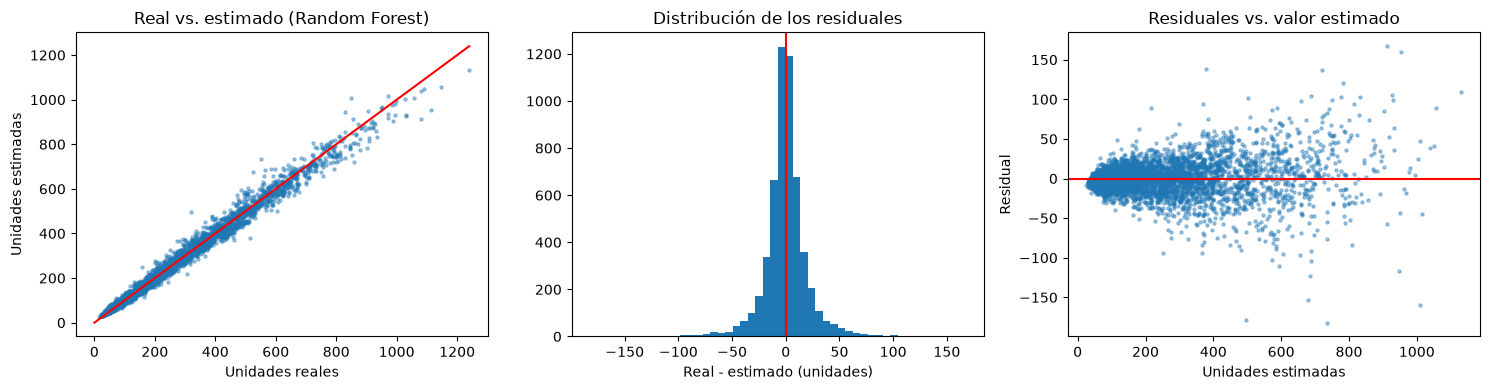

Residual promedio: 0.15 unidades
El 90% de los errores está entre -29.5 y 31.2 unidades


In [21]:
# Valores reales vs. estimados y residuales (error = real - estimado)
resultado['residual'] = resultado['units_sold'] - resultado['pronostico_rf']

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# 1) Real vs. estimado: si el modelo fuera perfecto, todos los puntos caerían en la línea roja
ax[0].scatter(resultado['units_sold'], resultado['pronostico_rf'], s=5, alpha=0.4)
maximo = resultado['units_sold'].max()
ax[0].plot([0, maximo], [0, maximo], color='red')
ax[0].set_title('Real vs. estimado (Random Forest)')
ax[0].set_xlabel('Unidades reales')
ax[0].set_ylabel('Unidades estimadas')

# 2) Distribución de los residuales: deberían estar centrados en 0
ax[1].hist(resultado['residual'], bins=50)
ax[1].axvline(0, color='red')
ax[1].set_title('Distribución de los residuales')
ax[1].set_xlabel('Real - estimado (unidades)')

# 3) Residuales vs. estimado: no debería haber un patrón
ax[2].scatter(resultado['pronostico_rf'], resultado['residual'], s=5, alpha=0.4)
ax[2].axhline(0, color='red')
ax[2].set_title('Residuales vs. valor estimado')
ax[2].set_xlabel('Unidades estimadas')
ax[2].set_ylabel('Residual')

plt.tight_layout()
plt.show()

print('Residual promedio:', round(resultado['residual'].mean(), 2), 'unidades')
print('El 90% de los errores está entre', round(resultado['residual'].quantile(0.05), 1), 'y', round(resultado['residual'].quantile(0.95), 1), 'unidades')

In [22]:
# Error del mejor modelo por región
por_region = resultado.groupby('region').apply(
    lambda g: round(np.abs(g['units_sold'] - g['pronostico_rf']).sum() / g['units_sold'].sum() * 100, 2))
print('WAPE (%) del Random Forest por región:')
print(por_region.sort_values())

WAPE (%) del Random Forest por región:
region
Ciudad de México                     5.20
Zona Metropolitana de Monterrey      5.72
Zona Metropolitana de Guadalajara    5.97
Bajío                                6.59
Noroeste                             7.30
Sur                                  7.44
Sureste                              7.73
dtype: float64


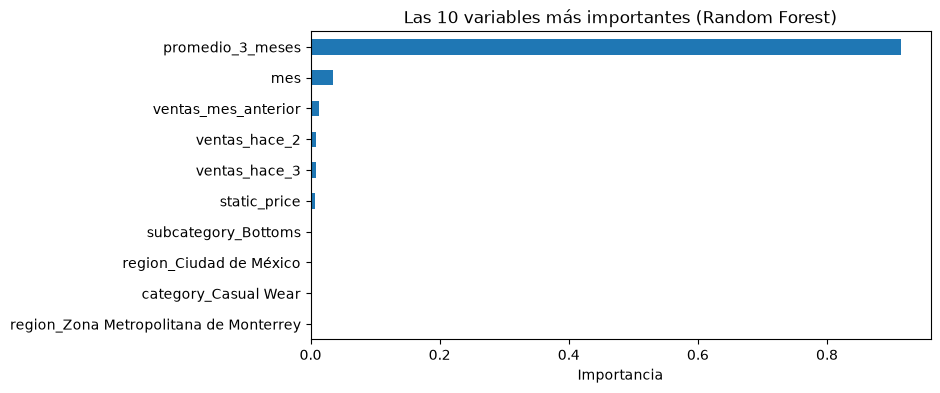

In [23]:
# ¿Qué variables usa más el modelo? (segundo método de selección de variables)
importancia = pd.Series(mejor_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
importancia.sort_values().plot(kind='barh')
plt.title('Las 10 variables más importantes (Random Forest)')
plt.xlabel('Importancia')
plt.show()

## 12. Impacto del preprocesamiento
Para medir qué tanto ayudó la preparación de los datos, se entrenan los dos modelos (partición 70/30, mejores hiperparámetros) con **4 grupos de variables**:
1. **Básicas:** región, categoría, subcategoría y mes (codificadas con One-Hot).
2. **Básicas + precio.**
3. **Básicas + ventas pasadas** (las variables creadas en el preprocesamiento).
4. **Todas** (el modelo final).

In [24]:
corte = '2025-07-01'
entrenamiento = datos['fecha'] < corte
prueba = datos['fecha'] >= corte

basicas = ['region', 'category', 'subcategory', 'mes']
rezagos = ['ventas_mes_anterior', 'ventas_hace_2', 'ventas_hace_3', 'promedio_3_meses']
grupos = {
    '1. Básicas': basicas,
    '2. Básicas + precio': basicas + ['static_price'],
    '3. Básicas + ventas pasadas': basicas + rezagos,
    '4. Todas (modelo final)': basicas + ['static_price'] + rezagos,
}
modelos = {
    'Random Forest': lambda: RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': lambda: XGBRegressor(n_estimators=800, learning_rate=0.03, max_depth=8, random_state=42),
}

comparacion = []
for nombre_modelo, crear_modelo in modelos.items():
    for nombre_grupo, columnas in grupos.items():
        X_grupo = pd.get_dummies(datos[columnas], columns=['region', 'category', 'subcategory'], dtype=int)
        modelo = crear_modelo()
        modelo.fit(X_grupo[entrenamiento], y[entrenamiento])
        fila = evaluar(y[prueba], modelo.predict(X_grupo[prueba]))
        fila.update({'Modelo': nombre_modelo, 'Variables': nombre_grupo})
        comparacion.append(fila)

pd.DataFrame(comparacion)[['Modelo', 'Variables', 'MAE', 'RMSE', 'WAPE (%)', 'R2']]

,Modelo,Variables,MAE,RMSE,WAPE (%),R2
0,Random Forest,1. Básicas,50.10,77.38,22.66,0.829
1,Random Forest,2. Básicas + precio,13.31,20.88,6.02,0.988
2,Random Forest,3. Básicas + ventas pasadas,13.42,20.92,6.07,0.987
3,Random Forest,4. Todas (modelo final),13.16,20.54,5.95,0.988
4,XGBoost,1. Básicas,50.09,77.34,22.66,0.829
5,XGBoost,2. Básicas + precio,16.60,23.21,7.51,0.985
6,XGBoost,3. Básicas + ventas pasadas,15.42,21.84,6.97,0.986
7,XGBoost,4. Todas (modelo final),14.10,20.32,6.38,0.988


**Interpretación:**
- Con solo las variables **básicas** el error es alto: el modelo sabe la región, la categoría y el mes, pero no sabe cuánto vende cada producto en particular.
- Al agregar el **precio**, el error baja muchísimo. Cada producto tiene un precio único, así que el precio funciona como "identificador" del producto, y como **las ventas de 2025 repiten las de 2024**, el modelo puede "recordar" cuánto vendió ese producto en el mismo mes del año pasado. Es un buen resultado, pero depende de que los datos se repitan.
- Al agregar las **ventas pasadas** (creadas en el preprocesamiento), el error también baja mucho **sin necesidad de identificar el producto**: el modelo aprende del nivel de ventas reciente, lo cual es más útil si en el futuro las ventas cambian o entran productos nuevos.
- Por eso el modelo final usa **todas** las variables.

## 13. Conclusiones
**¿Qué modelo y qué división funcionaron mejor?**

| Partición | Random Forest (mejor) | XGBoost (mejor) | Ingenuo | Pronóstico actual |
|---|---|---|---|---|
| 80/20 | **5.88 %** | 5.93 % | 19.8 % | 468 % |
| 70/30 | **5.95 %** | 6.38 % | 18.7 % | 471 % |
| 60/40 | **5.98 %** | 6.24 % | 18.2 % | 483 % |

*(WAPE: error total ÷ ventas totales)*

- **El mejor modelo es Random Forest** (100 árboles, sin límite de profundidad). Tiene el menor WAPE en las tres particiones, un MAE de ~13 unidades y un R² ≈ 0.99. XGBoost queda muy cerca, lo que confirma que el patrón en los datos es real.
- **La mejor división es 80/20**, aunque la diferencia entre particiones es mínima (5.88 % a 5.98 %). El modelo es **estable**: incluso entrenando con solo 13 meses (60/40) el error casi no cambia.
- **Los dos modelos le ganan por mucho al pronóstico actual** (~470 % de error, porque siempre espera ~6 veces más de lo que se vende) y al modelo ingenuo (~19 %).
- **Residuales:** están centrados en 0 (residual promedio ≈ 0.15 unidades) y el 90 % de los errores está entre −30 y +31 unidades. No hay un patrón claro, es decir, el modelo no sobrestima ni subestima de forma sistemática.

**¿Qué impacto tuvo el preprocesamiento?**
- **Crear las ventas pasadas** fue lo más importante. Con solo región, categoría, subcategoría y mes el error es de **22.7 %**; con las ventas pasadas baja a **6.1 %** en Random Forest y a 7.0 % en XGBoost.
- **El One-Hot Encoding** permitió usar región, categoría y subcategoría, que son texto.
- **Excluir las variables con fuga** (Ventas_Acumuladas, Venta_Promedio_Diaria, Cumplimiento, etc.) evita un modelo "perfecto" pero inútil en la vida real.
- **La normalización no fue necesaria** porque los modelos de árboles no dependen de la escala.

**¿Qué impacto tuvo el ajuste de hiperparámetros?**
- **Random Forest:** limitar la profundidad (`max_depth` = 8 y `min_samples_leaf` = 5) duplicó el error, de 5.95 % a 12.25 %. Los árboles completos distinguen mejor entre productos y regiones.
- **XGBoost:** fue más sensible. Con `max_depth` = 4 el error fue de 11.8 %, y con 800 árboles, `learning_rate` = 0.03 y `max_depth` = 8 bajó a 6.4 %. Es decir, el ajuste redujo el error casi a la mitad.

**Beneficio para DanuStore:** puede planear su stock según lo que realmente se va a vender en cada región y mes, en lugar de un pronóstico plano e inflado, y así reducir el sobreinventario (hoy el stock alcanza para ~208 días en lugar de ~34). Las variables más importantes son el promedio de ventas de los últimos 3 meses y el mes (temporada de noviembre y diciembre).

**Limitantes:**
1. **Las ventas de 2025 repiten casi exactamente las de 2024** (76.6 % de los registros son idénticos). Esto hace que el pronóstico sea más fácil de lo normal, por lo que hay que validar el modelo con datos nuevos antes de usarlo.
2. Las ventas son solo de clientes registrados.
3. El modelo pronostica **un mes adelante**; para varios meses habría que usar sus propios pronósticos como entrada.